# Week 2：预处理 + sklearn 基线

目标：
1. 用 Pipeline 做缺失值处理、标准化、独热编码；
2. 训练 Dummy / Logistic / RandomForest / XGBoost 四个模型；
3. 训练集 5 折交叉验证，测试集只评估一次；
4. 报告 AUROC、AUPRC、准确率、校准曲线和 bootstrap 95% CI；
5. 结果写入 results/baseline_metrics.csv。

In [2]:
# 导入依赖、定位路径、读取数据
from pathlib import Path
import numpy as np #numpy是科学计算的基础库，解决python原生list计算缓慢的问题
import pandas as pd #pandas是表格数据处理库，构建在nunpy之上，提供了DataFrame数据结构，类似于R语言中的data.frame
from sklearn.compose import ColumnTransformer 
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    confusion_matrix,
    roc_curve,
)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
while not(ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True,exist_ok=True)
train = pd.read_csv(ROOT / "data/raw/chowell_train.csv")
test = pd.read_csv(ROOT / "data/raw/chowell_test.csv")
print("ROOT:", ROOT)
print("train:", train.shape)
print("test:", test.shape)

ROOT: d:\TJH课题工作内容\clinicaltransformer\studyplan
train: (1184, 28)
test: (295, 28)


In [3]:
# 定义特征、目标、训练/测试矩阵

# 结局列:1 = responder, 0 = non-responder
TARGET = "Response (1:Responder; 0:Non-responder)"
# 16个数值/二值特征，对应论文中17个特征中除了癌种的部分
NUMERIC_FEATURES = [
    "Age",
    "Sex (1:Male; 0:Female)",
    "BMI",
    "Stage (1:IV; 0:I-III)",
    "NLR",
    "Platelets",
    "HGB",
    "Albumin",
    "Drug (1:Combo; 0:PD1/PDL1orCTLA4)",
    "TMB",
    "FCNA",
    "HED",
    "HLA_LOH",
    "MSI (1:Unstable; 0:Stable_Indeterminate)",
    "MSI_SCORE",
    "Chemo_before_IO (1:Yes; 0:No)",
]
# 癌种是类别变量，不能当连续数字使用，做one-hot编码
CATEGORICAL_FEATURES = ["Cancer_type_grouped_2",]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X_train = train[FEATURES].copy()
y_train = train[TARGET].astype(int)
X_test = test[FEATURES].copy()
y_test = test[TARGET].astype(int)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("阳性率（训练集）:", round(y_train.mean(), 4))
print("阳性率（测试集）:", round(y_test.mean(), 4))

X_train: (1184, 17)
X_test : (295, 17)
阳性率（训练集）: 0.2694
阳性率（测试集）: 0.3051


In [4]:
# 预处理pipeline + 四个模型

# 数值特征：缺失使用中位数填补（本部分无缺失值，但保留以增强稳健性），然后标准化
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
# 类别特征：缺失使用最频繁值填补，然后one-hot编码；handle_unknown="ignore"是为了避免测试集出现训练集中没有的类别时报错
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
# 把两类特征拼起来；remainder="drop" 表示不在列表里的列全部丢弃
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("cat", categorical_pipe, CATEGORICAL_FEATURES),
], remainder="drop")


# 阳性只占约 27%，用 scale_pos_weight 让 XGBoost 更关注阳性
# 相当于给正样本乘一个放大系数，让模型把阳性样本的错误放大
# 即：若scale_pos_weight=1，那么正负样本同样对待；若scale_pos_weight=2.7,那么正样本的错误会被放大 2.7 倍
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 3))

# 详见“python常用库”文件中的“sklearn模型基线”部分
models = {
     # 无技能基线：永远预测训练集的阳性率；AUROC 应接近 0.5
    "Dummy (prior)": DummyClassifier(strategy="prior"),
     # 线性基线：可解释性最好；class_weight="balanced" 处理类别不平衡
    "LogisticRegression": LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
     # 树模型基线
    "RandomForest": RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}
# XGBoost 已安装则使用；没有安装时回退到 sklearn 的 HistGradientBoosting
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    models["HistGradientBoosting"] = HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE,
    )
print("models:", list(models.keys()))

scale_pos_weight: 2.712
models: ['Dummy (prior)', 'LogisticRegression', 'RandomForest', 'XGBoost']


In [5]:
# 训练集5折交叉验证（不看测试集）
  
# 把训练集切成 5 份，轮流拿其中 1 份当验证集、剩下 4 份当训练集，训练 5 次，取 5 个分数的平均值作为模型表现
  
# 分类任务常用指标：
  # AUROC：整体区分能力；
  # AUPRC：阳性少时更有参考价值；
  # accuracy：在本数据阳性率 27% 的情况下容易高估模型。
  # 详见python常用库中的模型划分指标部分
SCORING = {
    "auroc": "roc_auc",
    "auprc": "average_precision",
    "accuracy": "accuracy",
}

#使用stratifiedFold交叉验证，保证每一折中阳性样本比例与整体数据集相同（即每折阳性比例≈0.27）
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
cv_results = {}

for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model),
    ])
    # 只在训练集内部做5折，测试集不参与
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,          # 避免和外层/模型内部并行冲突
        error_score="raise",
    )
    cv_results[name] = scores
    print(f"\n{name}")
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        print(f"  {metric}: {values.mean():.4f} ± {values.std():.4f}")


Dummy (prior)
  auroc: 0.5000 ± 0.0000
  auprc: 0.2694 ± 0.0012
  accuracy: 0.7306 ± 0.0012

LogisticRegression
  auroc: 0.7041 ± 0.0127
  auprc: 0.4810 ± 0.0215
  accuracy: 0.6529 ± 0.0267

RandomForest
  auroc: 0.7058 ± 0.0083
  auprc: 0.4882 ± 0.0198
  accuracy: 0.6976 ± 0.0131

XGBoost
  auroc: 0.6599 ± 0.0290
  auprc: 0.4412 ± 0.0253
  accuracy: 0.6943 ± 0.0159


解读五折交叉验证结果：
1. Dummy数字落在理论值，评估pipeline是可信的
   AUROC = 0.5，因为随机排序，所以理论值就是0.5，无数据泄露
   AUPRC(阳性率) + Accuracy(阴性率) = 1，表明交叉验证//指标计算/标签编码没问题
   确定了AUPRC的及格线为0.269
2. 信号强度中等，需要进一步调参(以LogisticRegression为例)
   AUROC = 0.7041，表明区分能力为中等，要0.8+才算好
   AUPRC = 0.481，比基线0.269显著提升，表明阳性类能被有效识别
3. LR ≈ RF(AUROC与AUPRC的差距均很小)——非线性信号捕捉并不能显著提升预测能力
   表明数据中的预测信号几乎均为线性的，因此后续继续无需继续加模型复杂度
   想进一步提升预测能力需要：
     特征工程(交互项、比率、分箱、目标编码、领域特征等)
     更多、更好的数据
     提升标签质量
4. XGBoost更差————代表排查信号
   (1)scale_pos_weight可能为了提高recall而损害AUROC/AUPRC，即可能为了多抓阳性而牺牲了整体的排序质量
   (2)XGBClassifier的默认超参数可能在小数据/噪声大时会过拟合(XGB方差是RF的3.5倍是过拟合的典型征兆)，建议更浅、更多树+更低学习率+早停
   (3)可能数据量太小导致抖动
5. Accuracy在Dummy中最高，证明不平衡任务不能只看accuracy选择模型

In [6]:
# 测试集评估+bootstrap 95%Cl
def bootstrap_ci(y_true, y_prob, metric_fn, n_boot=1000, seed=RANDOM_STATE):
    # 参数包括真实标签、预测概率、要算的指标函数、bootstrap重采样次数(默认1000)、随机种子
    """按样本有放回重采样，返回 metric 的 2.5% 和 97.5% 分位数。"""
    rng = np.random.default_rng(seed) #创建局部随机数生成器，用seed保证可复现，且不污染全局
    y_true = np.asarray(y_true) #统一为numpy数组，方便索引
    y_prob = np.asarray(y_prob)
    n = len(y_true) #测试集样本数

    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n) #从【0，n）中有放回地抽n个整数
        yt, yp = y_true[idx], y_prob[idx] #yt, yp即为与原测试集同样大小，但构成不同的伪测试集
#原测试集:  [样本1, 样本2, 样本3, 样本4, 样本5]
#重采样后:  [样本4, 样本1, 样本4, 样本4, 样本2]
#目的：因为我们只有一个测试集，无法真的去收集 1000 个新测试集。Bootstrap 的统计学依据是：从现有样本中有放回重采样，可以模拟"从总体中重新抽样"的波动，从而估计指标的抽样误差。

        # 如果重采样后只剩一个类别，AUROC 无法计算，跳过
        if len(np.unique(yt)) < 2:
            continue

        values.append(metric_fn(yt, yp)) #在伪测试集上算一次指标，收进列表，1000次后values即为指标的经验分布

    return np.percentile(values, [2.5, 97.5]) #取values的2.5%和97.5%分位数作为95%置信区间

#这两个只是薄包装。包装一层是因为 bootstrap_ci 需要一个"只接收 (y_true, y_prob) 两个参数"的统一接口——包装后签名一致，就能当参数传进去。
def auroc_fn(y_true, y_prob):
    return roc_auc_score(y_true, y_prob)
def auprc_fn(y_true, y_prob):
    return average_precision_score(y_true, y_prob)

#Accuracy 不能直接吃概率，必须先按阈值切成 0/1
def accuracy_fn(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)#y_prob >= 0.5 → 布尔数组，.astype(int) → 转成 0/1 数组
    return accuracy_score(y_true, y_pred)#与真实标签比较


test_predictions = {} #只存原始概率 y_prob。方便后续画 ROC/PR 曲线、做 DeLong 检验、配对 bootstrap、重新调阈值
test_metrics = {} #存所有指标 + CI + 硬标签 y_pred。供打印、画混淆矩阵、写报告

for name, model in models.items(): #遍历前面构建的models字典，name是模型名，model是模型对象

#构建pipeline，把预处理和模型组合起来
#这一步保证：
# 1.预处理只fit在训练集上，pipe.fit(X_train, y_train)时，preprocessor只会看到训练集，测试集不会参与fit
# 2.四个模型走完全相同的预处理链路，比较公平
# 3.推理时自动复用训练时的参数：pipe.predict_proba(X_test) 内部用训练集算出的均值/方差去 transform 测试集
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model),
    ])

# 用全部训练集拟合，在测试集上只评估一次
# 与5折CV相比，使用了全部的训练集数据，在测试集上只评估一次，相当于进行终极考核
    pipe.fit(X_train, y_train)

#进行概率预测
    y_prob = pipe.predict_proba(X_test)[:, 1]
    test_predictions[name] = y_prob

#直接在完整测试集上算这3个指标，此为最终报告的数值
    auroc = roc_auc_score(y_test, y_prob)
    auprc = average_precision_score(y_test, y_prob)
    acc = accuracy_score(y_test, (y_prob >= 0.5).astype(int))
#各自跑1000次重采样，由于三次调用都默认seed=RANDOM_STATE，故三个指标和四个模型的重采样索引是一样的，CIs是配对的，可直接横向比较
    auroc_ci = bootstrap_ci(y_test, y_prob, auroc_fn)
    auprc_ci = bootstrap_ci(y_test, y_prob, auprc_fn)
    acc_ci = bootstrap_ci(y_test, y_prob, accuracy_fn)
#保存指标
    test_metrics[name] = {
        "auroc": auroc,
        "auroc_ci": auroc_ci,
        "auprc": auprc,
        "auprc_ci": auprc_ci,
        "accuracy": acc,
        "accuracy_ci": acc_ci,
        "y_pred": (y_prob >= 0.5).astype(int),
    }

    print(f"\n{name}")
    print(f"  AUROC : {auroc:.4f}  (95% CI {auroc_ci[0]:.4f}–{auroc_ci[1]:.4f})")
    print(f"  AUPRC : {auprc:.4f}  (95% CI {auprc_ci[0]:.4f}–{auprc_ci[1]:.4f})")
    print(f"  Acc   : {acc:.4f}  (95% CI {acc_ci[0]:.4f}–{acc_ci[1]:.4f})")
    print("  Confusion matrix:")
    print(confusion_matrix(y_test, test_metrics[name]["y_pred"]))


Dummy (prior)
  AUROC : 0.5000  (95% CI 0.5000–0.5000)
  AUPRC : 0.3051  (95% CI 0.2508–0.3525)
  Acc   : 0.6949  (95% CI 0.6475–0.7492)
  Confusion matrix:
[[205   0]
 [ 90   0]]

LogisticRegression
  AUROC : 0.7862  (95% CI 0.7324–0.8416)
  AUPRC : 0.5967  (95% CI 0.5019–0.7062)
  Acc   : 0.7220  (95% CI 0.6746–0.7696)
  Confusion matrix:
[[152  53]
 [ 29  61]]

RandomForest
  AUROC : 0.8055  (95% CI 0.7529–0.8578)
  AUPRC : 0.6757  (95% CI 0.5838–0.7638)
  Acc   : 0.7627  (95% CI 0.7153–0.8102)
  Confusion matrix:
[[165  40]
 [ 30  60]]

XGBoost
  AUROC : 0.7708  (95% CI 0.7104–0.8321)
  AUPRC : 0.6408  (95% CI 0.5481–0.7315)
  Acc   : 0.7593  (95% CI 0.7085–0.8102)
  Confusion matrix:
[[171  34]
 [ 37  53]]


从结果来看，RandomForest在AUROC/AUPRC/Acc上均取得最高分，是目前待确认的最优模型
待解决问题：
1. 在训练集和测试集中，XGBoost表现均很差，似乎不符合直觉，需要进一步排查是否参数设置有问题
2. 测试集的表现在几个模型均优于训练集的CV，需要排查切分是否有问题/有无预处理泄露

In [14]:
#保存结果表+打印
#这一部分将5折CV结果+测试集结果统一整理为长标，并存储为csv
rows = [] #创建一个空列表，收集所有行

# 交叉验证结果：value = 均值，ci_low/high = 均值 ± 标准差
for name, scores in cv_results.items():
    for metric in SCORING:
        values = scores[f"test_{metric}"] #f"test_{metric}" 就是把 metric="auroc" 拼成 "test_auroc"，取出5 个折的 AUROC 数组
        rows.append({ #为每个模型指标生成1行
            "model": name,
            "endpoint": "Response",
            "split": "train_cv",
            "metric": metric,
            "value": values.mean(),
            "ci_low": values.mean() - values.std(),
            "ci_high": values.mean() + values.std(), #并非真正的置信区间，只是均值±1sd
            "notes": "5-fold stratified CV; mean ± SD",
        })

# 测试集结果：value = 点估计，ci_low/high = bootstrap 95% CI
for name, metrics in test_metrics.items():
    for metric in ["auroc", "auprc", "accuracy"]:#不用 SCORING，是因为 test_metrics 的键是短名（auroc）而不是 CV 的 test_auroc，并且顺序固定。
        ci = metrics[f"{metric}_ci"]
        rows.append({
            "model": name,
            "endpoint": "Response",
            "split": "test", #使用split区分源
            "metric": metric,
            "value": metrics[metric],
            "ci_low": ci[0],
            "ci_high": ci[1],
            "notes": "test set; 1000x bootstrap 95% CI", #使用notes区分区间类型
        })

metrics_df = pd.DataFrame(rows) #将列表转成表格
out_path = RESULTS / "baseline_metrics.csv"
metrics_df.to_csv(out_path, index=False)

print("saved:", out_path) #打印保存路径

# 横向对比测试集结果
summary = (
    metrics_df[metrics_df["split"] == "test"] #过滤，只保留测试集
    .pivot(index="model", columns="metric", values="value")#长表转宽表。pivot 要求 (model, metric) 组合唯一。这里每个模型每个指标只有一行（因为已经 split=="test"），所以安全。如果有重复，会报 ValueError: Index contains duplicate entries，那就得改用 pivot_table(aggfunc="first")
    [["auroc", "auprc", "accuracy"]]#调整列顺序
    .sort_values("auroc", ascending=False)#按照AUROC降序排列
)
summary_path = RESULTS / "test_metrics_summary.csv"
summary.round(4).to_csv(summary_path, index=True, index_label="model" )
print("\nTest-set comparison:")
print(summary.round(4).to_string())

saved: d:\TJH课题工作内容\clinicaltransformer\studyplan\results\baseline_metrics.csv

Test-set comparison:
metric               auroc   auprc  accuracy
model                                       
RandomForest        0.8055  0.6757    0.7627
LogisticRegression  0.7862  0.5967    0.7220
XGBoost             0.7708  0.6408    0.7593
Dummy (prior)       0.5000  0.3051    0.6949


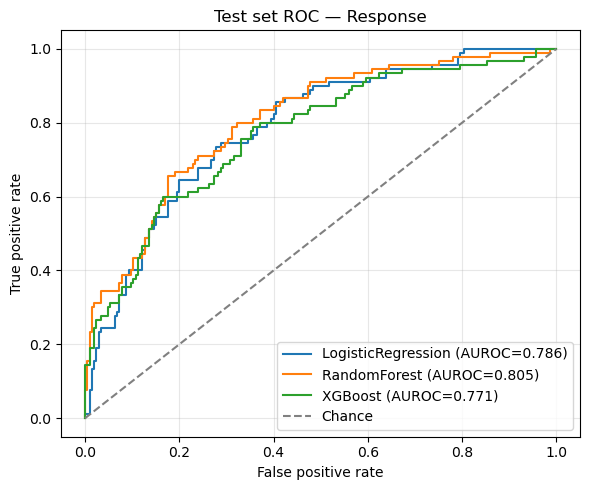

In [15]:
#ROC曲线
fig, ax = plt.subplots(figsize=(6, 5)) #创建画布

for name in models:
    # Dummy 的 ROC 是一条对角线，画出来意义不大
    if name.startswith("Dummy"):
        continue

    y_prob = test_predictions[name] #取出该模型的预测概率
   
    #计算ROC坐标点
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    #单独计算auc用于图例
    auc_value = roc_auc_score(y_test, y_prob)
    #画曲线
    ax.plot(fpr, tpr, label=f"{name} (AUROC={auc_value:.3f})")

#画随机猜测参考线(一条从(0,0)到(1,1)的参考线)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")

#设置坐标轴
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test set ROC — Response")

#图例与网格
ax.legend(loc="lower right") #图例放右下角防止遮挡图像
ax.grid(alpha=0.3) #网格透明度0.3

fig.tight_layout() #自动调整子图边距，防止被裁掉
fig.savefig(RESULTS / "w02_roc.png", dpi=300, bbox_inches="tight") #默认300像素为出版级清晰度，bbox_inches=tight裁掉多余空白边使导出的图更紧凑
plt.show()

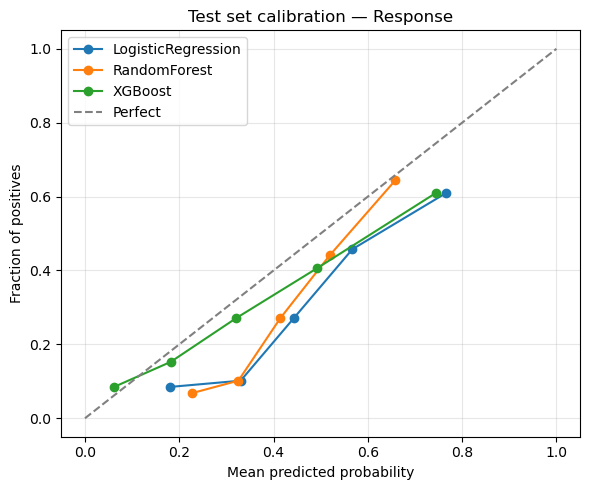

In [16]:
#校准曲线
#ROC回答模型排序能力，校准曲线则回答概率说的准不准的问题
fig, ax = plt.subplots(figsize=(6, 5))

for name in models:
    if name.startswith("Dummy"):
        continue

    y_prob = test_predictions[name]#取出测试集上每个样本的正类概率，长度295

    # 校准曲线：横轴是预测概率，纵轴是实际阳性比例
    # 越接近对角线，说明“说 30% 就真的约 30%”
    #callibration_curve把预测概率分成n_bins个bin，统计每个bin内的mean_pred(bin内预测概率平均值，作为横坐标)和frac_pos(bin内的实际阳性样本比例，作为纵坐标)
    frac_pos, mean_pred = calibration_curve(
        y_test,
        y_prob,
        n_bins=5,
        #strategy默认为uniform，按照概率等宽切割，但概率集中某些bin时会导致某些bin内样本太少
        #使用quantlie可以按照概率分位数切，每个bin样本数大致相同
        strategy="quantile", 
    )

    ax.plot(mean_pred, frac_pos, marker="o", label=name) #marker="o"是指每个bin画一个圆点，强调分箱统计而非连续函数

#画完美校准的参考线
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect")
#写坐标轴与标题
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Test set calibration — Response")
#图例与网格
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "w02_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

解读callibration curve
1. 点在对角线下方：高估阳性概率，可能是由于scale_pos_weight/class_weight='balanced'或树模型过度自信
2. 点在对角线上方：低估阳性概率，可能由于类别权重＜1，正则化过强
3. S形弯曲：有概率的压缩/膨胀，一般见于逻辑回归在极端概率处

注：由于只有295条数据，故分箱法已经足够，更现代的做法是平滑校准曲线(loess/spline)

In [18]:
#逻辑回归系数/特征方向
#这一部分的目的是回答：逻辑回归认为哪些特征最重要？方向是正还是负？
#具体操作是：重新用 preprocessor + LogisticRegression 训练一次，取出标准化后的系数，按绝对值排序，打印影响最大的前 15 个特征
# 以 LogisticRegression 为例：标准化后，系数绝对值越大，说明该特征对预测影响越大

#重新组装pipeline
logit_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", models["LogisticRegression"]),
])

#训练，用全部训练集训练，prep先fit(学中位数、均值、标准差、类别列表等)，再transform，然后将变换的矩阵喂给逻辑回归
logit_pipe.fit(X_train, y_train)

#获取特征名，这一步是为了将第i个系数和第i个特征名对应起来，否则没法解释
feature_names = logit_pipe.named_steps["prep"].get_feature_names_out()

#取出系数
coefs = logit_pipe.named_steps["model"].coef_[0]

#组装DataFrame
importance = (
    pd.DataFrame({"feature": feature_names, "coef": coefs})
    .assign(abs_coef=lambda d: d["coef"].abs()) #新增一列系数绝对值，这一列只用于排序
    .sort_values("abs_coef", ascending=False)# 按照绝对值降序排列
    .head(15)
)

importance.to_csv(
    RESULTS / "w02_logit_coefs_top15.csv",
    index=False,
    encoding="utf-8-sig",
)
print("saved:", RESULTS / "w02_logit_coefs_top15.csv")
print(importance[["feature", "coef"]].to_string(index=False))

saved: d:\TJH课题工作内容\clinicaltransformer\studyplan\results\w02_logit_coefs_top15.csv
                               feature      coef
 cat__Cancer_type_grouped_2_Pancreatic -1.551415
      cat__Cancer_type_grouped_2_Renal  0.857104
    cat__Cancer_type_grouped_2_Bladder -0.771917
 cat__Cancer_type_grouped_2_Esophageal  0.713994
                              num__TMB  0.654336
                          num__Albumin  0.422570
 cat__Cancer_type_grouped_2_Colorectal -0.392692
    num__Chemo_before_IO (1:Yes; 0:No) -0.380785
       cat__Cancer_type_grouped_2_SCLC  0.345814
    cat__Cancer_type_grouped_2_Gastric  0.332593
    cat__Cancer_type_grouped_2_Ovarian -0.295486
cat__Cancer_type_grouped_2_Endometrial  0.284703
cat__Cancer_type_grouped_2_Head & Neck  0.273236
      cat__Cancer_type_grouped_2_NSCLC  0.227120
                              num__NLR -0.221796
